# PPO (Proximal Policy Optimization): blood delivery drone


## 1. Setup

In [1]:
import os
import sys
import random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical
from collections import deque

# Run from the project root so that `environment/` can be imported.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from environment.custom_env import BloodDroneEnv, MASK_START, mask_scores

env = BloodDroneEnv()
STATE_SIZE = env.observation_space.shape[0]   # 43 numbers describe the drone and its surroundings
NUM_ACTIONS = env.action_space.n              # 9 actions
print("State size:", STATE_SIZE, "| Actions:", NUM_ACTIONS)


State size: 43 | Actions: 9


## 2. Helper functions

`make_net` builds a small neural network.

In [2]:
EPISODES = 500          # training episodes for every experiment
REWARD_SCALE = 0.1      # smaller rewards for training only (helps stability)


def make_net(inputs, hidden, outputs):
    """A small neural network: inputs -> hidden layers -> one score per action."""
    layers, size = [], inputs
    for h in hidden:
        layers += [nn.Linear(size, h), nn.ReLU()]
        size = h
    layers.append(nn.Linear(size, outputs))
    return nn.Sequential(*layers)


## 3. The PPO agent

`train_ppo` trains one agent for 500 episodes and returns the reward of every episode and the loss values.

In [3]:
def train_ppo(config, episodes=EPISODES, lam=0.95):
    """Train one PPO agent. Returns the reward of every episode and the loss values."""
    random.seed(0); np.random.seed(0); torch.manual_seed(0)
    env = BloodDroneEnv(practice=0.8)   # the same training setting as training/ppo_training.py

    actor = make_net(STATE_SIZE, (64, 64), NUM_ACTIONS)    # chooses actions
    critic = make_net(STATE_SIZE, (64, 64), 1)              # estimates how good a state is
    optimizer = optim.Adam(list(actor.parameters()) + list(critic.parameters()), lr=config["lr"])
    rewards, losses = [], []
    finished = 0

    while finished < episodes:
        # 1. Collect whole episodes until there are about batch_steps steps.
        states, actions, old_log_probs = [], [], []
        step_rewards, values, dones = [], [], []
        state, _ = env.reset()
        total = 0.0
        while True:
            obs = torch.tensor(state)
            with torch.no_grad():
                dist = Categorical(logits=mask_scores(actor(obs), obs))
                action = dist.sample()
                value = critic(obs).item()
            state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated
            states.append(obs)
            actions.append(action)
            old_log_probs.append(dist.log_prob(action).item())
            step_rewards.append(reward * REWARD_SCALE)
            values.append(value)
            dones.append(float(done))
            total += reward
            if done:
                rewards.append(total)
                finished += 1
                total = 0.0
                state, _ = env.reset()
                if len(states) >= config["batch_steps"]:
                    break

        # 2. Advantage: how much better each step turned out than the critic expected.
        advantages, last = [], 0.0
        for t in reversed(range(len(step_rewards))):
            next_value = 0.0 if dones[t] else values[t + 1]
            delta = step_rewards[t] + config["gamma"] * next_value - values[t]
            last = delta + config["gamma"] * lam * (1 - dones[t]) * last
            advantages.insert(0, last)
        advantages = torch.tensor(advantages, dtype=torch.float32)
        returns = advantages + torch.tensor(values, dtype=torch.float32)
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        states = torch.stack(states)
        actions = torch.stack(actions)
        old_log_probs = torch.tensor(old_log_probs)

        # 3. Improve the actor and critic for a few passes, with the clipping rule.
        for _ in range(config["epochs"]):
            dist = Categorical(logits=mask_scores(actor(states), states))
            ratio = torch.exp(dist.log_prob(actions) - old_log_probs)
            clipped = torch.clamp(ratio, 1 - config["clip_epsilon"], 1 + config["clip_epsilon"])
            policy_loss = -torch.min(ratio * advantages, clipped * advantages).mean()
            value_loss = F.mse_loss(critic(states).squeeze(-1), returns)
            loss = policy_loss + 0.5 * value_loss - config["entropy_coeff"] * dist.entropy().mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

    return rewards[:episodes], losses   # exactly the number of episodes asked for


## 4. The 10 experiments

Experiment 1 is the baseline. In each of the other nine experiments only one hyperparameter is changed.

In [4]:
ppo_configs = [
    {"name": "PPO-1", "lr": 0.0003, "gamma": 0.99, "clip_epsilon": 0.2, "epochs": 4, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-2", "lr": 0.001, "gamma": 0.99, "clip_epsilon": 0.2, "epochs": 4, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-3", "lr": 0.0001, "gamma": 0.99, "clip_epsilon": 0.2, "epochs": 4, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-4", "lr": 0.0003, "gamma": 0.95, "clip_epsilon": 0.2, "epochs": 4, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-5", "lr": 0.0003, "gamma": 0.999, "clip_epsilon": 0.2, "epochs": 4, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-6", "lr": 0.0003, "gamma": 0.99, "clip_epsilon": 0.1, "epochs": 4, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-7", "lr": 0.0003, "gamma": 0.99, "clip_epsilon": 0.3, "epochs": 4, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-8", "lr": 0.0003, "gamma": 0.99, "clip_epsilon": 0.2, "epochs": 8, "entropy_coeff": 0.01, "batch_steps": 400},
    {"name": "PPO-9", "lr": 0.0003, "gamma": 0.99, "clip_epsilon": 0.2, "epochs": 4, "entropy_coeff": 0.001, "batch_steps": 400},
    {"name": "PPO-10", "lr": 0.0003, "gamma": 0.99, "clip_epsilon": 0.2, "epochs": 4, "entropy_coeff": 0.02, "batch_steps": 400},
]

## 5. Run the experiments

In [5]:
results = []      # one row per experiment
curves = {}       # reward of every episode, for the plots

for config in ppo_configs:
    rewards, losses = train_ppo(config)
    curves[config["name"]] = rewards
    results.append({
        "experiment": config["name"],
        "average reward": round(float(np.mean(rewards)), 1),
        "last 100": round(float(np.mean(rewards[-100:])), 1),
        "loss": round(float(np.mean(losses)), 3),
    })
    print(config["name"], "| average:", results[-1]["average reward"], "| last 100:", results[-1]["last 100"], "| loss:", results[-1]["loss"])

PPO-1 | average: -106.7 | last 100: -95.0 | loss: 3.621


PPO-2 | average: -99.5 | last 100: -92.7 | loss: 2.135


PPO-3 | average: -113.0 | last 100: -114.8 | loss: 6.607


PPO-4 | average: -111.6 | last 100: -106.8 | loss: 2.774


PPO-5 | average: -106.3 | last 100: -85.1 | loss: 3.919


PPO-6 | average: -106.1 | last 100: -90.0 | loss: 3.576


PPO-7 | average: -100.6 | last 100: -84.4 | loss: 4.047


PPO-8 | average: -101.4 | last 100: -82.0 | loss: 2.518


PPO-9 | average: -101.2 | last 100: -87.9 | loss: 3.452


PPO-10 | average: -111.3 | last 100: -106.2 | loss: 3.342


## 6. Results

In [6]:
print(f"{'experiment':<14}{'average reward':>16}{'last 100':>12}{'loss':>10}")
for row in results:
    print(f"{row['experiment']:<14}{row['average reward']:>16}{row['last 100']:>12}{row['loss']:>10}")

experiment      average reward    last 100      loss
PPO-1                   -106.7       -95.0     3.621
PPO-2                    -99.5       -92.7     2.135
PPO-3                   -113.0      -114.8     6.607
PPO-4                   -111.6      -106.8     2.774
PPO-5                   -106.3       -85.1     3.919
PPO-6                   -106.1       -90.0     3.576
PPO-7                   -100.6       -84.4     4.047
PPO-8                   -101.4       -82.0     2.518
PPO-9                   -101.2       -87.9     3.452
PPO-10                  -111.3      -106.2     3.342


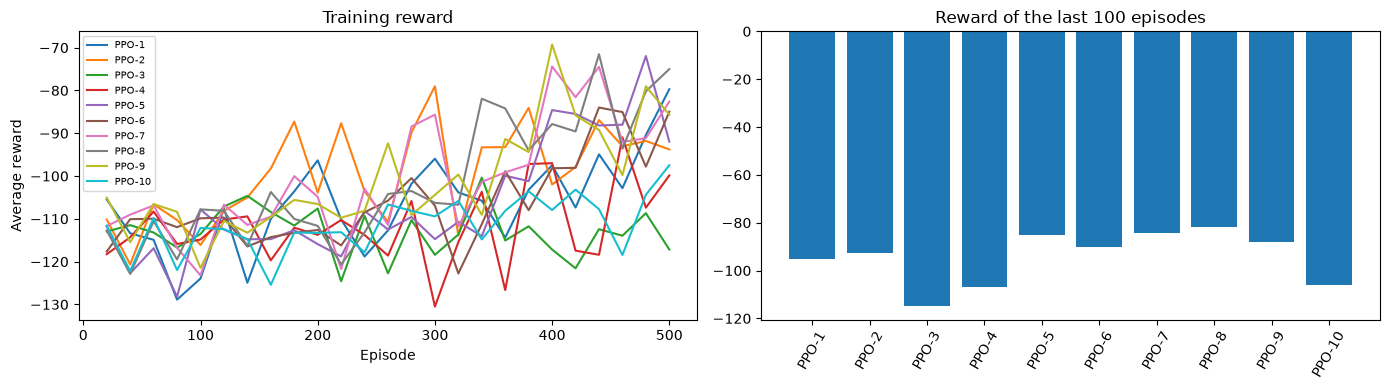

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# learning curves (average of every 20 episodes)
for name, rewards in curves.items():
    smooth = [np.mean(rewards[i:i + 20]) for i in range(0, len(rewards), 20)]
    axes[0].plot(range(20, len(rewards) + 1, 20), smooth, label=name)
axes[0].set_title("Training reward")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Average reward")
axes[0].legend(fontsize=7)

# reward of the last 100 episodes of every experiment (what the agent learned)
axes[1].bar([row["experiment"] for row in results], [row["last 100"] for row in results])
axes[1].set_title("Reward of the last 100 episodes")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 7. Best hyperparameters

The best experiment is the one with the highest average reward in its last 100 episodes, because that shows what the agent has learned (the early episodes are mostly random exploration). These values are the ones to use in `training/ppo_training.py`.

In [8]:
# the best experiment has the highest reward in its last 100 episodes (smaller loss breaks a tie)
best = sorted(results, key=lambda row: (-row["last 100"], row["loss"]))[0]
best_config = next(c for c in ppo_configs if c["name"] == best["experiment"])

print("Best experiment:", best["experiment"])
print("Last 100 episodes:", best["last 100"], "| average:", best["average reward"], "| loss:", best["loss"])
print("Best hyperparameters:")
for key, value in best_config.items():
    if key != "name":
        print("  ", key, "=", value)

Best experiment: PPO-8
Last 100 episodes: -82.0 | average: -101.4 | loss: 2.518
Best hyperparameters:
   lr = 0.0003
   gamma = 0.99
   clip_epsilon = 0.2
   epochs = 8
   entropy_coeff = 0.01
   batch_steps = 400
